In [86]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy.stats as stats

In [87]:
sns.load_dataset('tips')

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [88]:
tips = sns.load_dataset('tips')

In [89]:
np.unique(tips['time'])

array(['Dinner', 'Lunch'], dtype=object)

### Predict the Tip Ammount 
- based on the total bill based on the columns

In [90]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [91]:
df_encoding = pd.get_dummies(tips, columns=['sex', 'smoker', 'day', 'time'], drop_first=True, dtype=int)

In [92]:
df_encoding

,total_bill,tip,size,sex_Female,smoker_No,day_Fri,day_Sat,day_Sun,time_Dinner
0,16.99,1.01,2,1,1,0,0,1,1
1,10.34,1.66,3,0,1,0,0,1,1
2,21.01,3.50,3,0,1,0,0,1,1
3,23.68,3.31,2,0,1,0,0,1,1
4,24.59,3.61,4,1,1,0,0,1,1
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,3,0,1,0,1,0,1
240,27.18,2.00,2,1,0,0,1,0,1
241,22.67,2.00,2,0,0,0,1,0,1
242,17.82,1.75,2,0,1,0,1,0,1


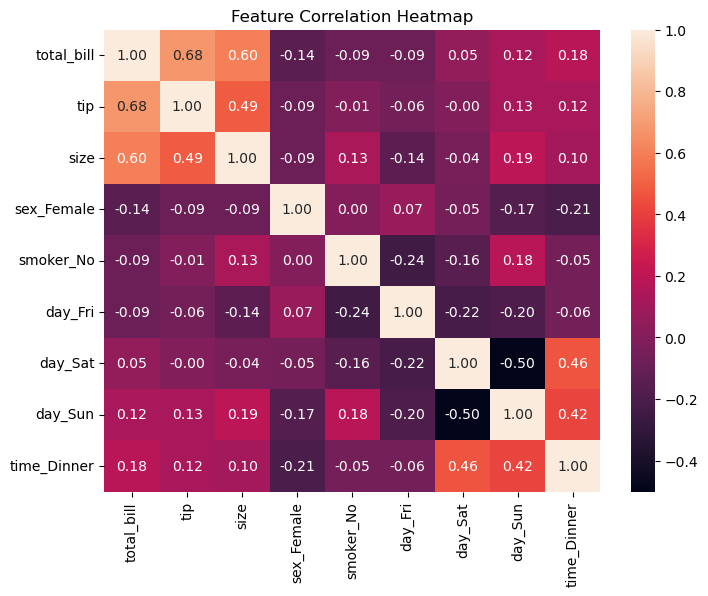

In [93]:
corr = df_encoding.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

In [94]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression



In [95]:
x = df_encoding['total_bill'].values.reshape(-1, 1)
y = df_encoding['tip'].values.reshape(-1, 1)

In [96]:
df_encoding

,total_bill,tip,size,sex_Female,smoker_No,day_Fri,day_Sat,day_Sun,time_Dinner
0,16.99,1.01,2,1,1,0,0,1,1
1,10.34,1.66,3,0,1,0,0,1,1
2,21.01,3.50,3,0,1,0,0,1,1
3,23.68,3.31,2,0,1,0,0,1,1
4,24.59,3.61,4,1,1,0,0,1,1
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,3,0,1,0,1,0,1
240,27.18,2.00,2,1,0,0,1,0,1
241,22.67,2.00,2,0,0,0,1,0,1
242,17.82,1.75,2,0,1,0,1,0,1


In [97]:
X = df_encoding[["total_bill", "size", "sex_Female", "smoker_No", "day_Fri", "day_Sat", "day_Sun", "time_Dinner"]].values
Y = df_encoding["tip"].values.reshape(-1, 1)

xtrain, xtest, ytrain, ytest = train_test_split(X, Y, test_size=0.2, random_state=42)

In [98]:
linear_model = LinearRegression().fit(xtrain, ytrain)
linear_model.score(xtest, ytest)

0.43730181943482516

### Scenario: 3 people 2 men, 1 woman, each ordering a burger
Predict the tip amount they will give using the trained regression model, and visualize feature correlations with a heatmap.

In [99]:
burger_price = 12.0
total_bill = burger_price * 3
row = {
    "total_bill": total_bill,
    "size": 3,
    "sex_Female": 1,
    "smoker_No": 1,
    "day_Fri": 0,
    "day_Sat": 0,
    "day_Sun": 0,
    "time_Dinner": 1,
}
X_new = np.array([[row[c] for c in ["total_bill","size","sex_Female","smoker_No","day_Fri","day_Sat","day_Sun","time_Dinner"]]])
pred_tip = linear_model.predict(X_new)
print("Predicted tip:", round(float(pred_tip[0][0]), 2))

Predicted tip: 4.66


### KNN Regression
- Predict tip using K-Nearest Neighbors on the same features.

In [100]:
from sklearn.neighbors import KNeighborsRegressor


In [101]:
knn_model = KNeighborsRegressor(n_neighbors=5).fit(xtrain, ytrain)
knn_model.score(xtest, ytest)


0.3078597253641333

In [102]:
knn_pred = knn_model.predict(X_new)
print("KNN predicted tip:", round(float(knn_pred[0][0]), 2))


KNN predicted tip: 4.74


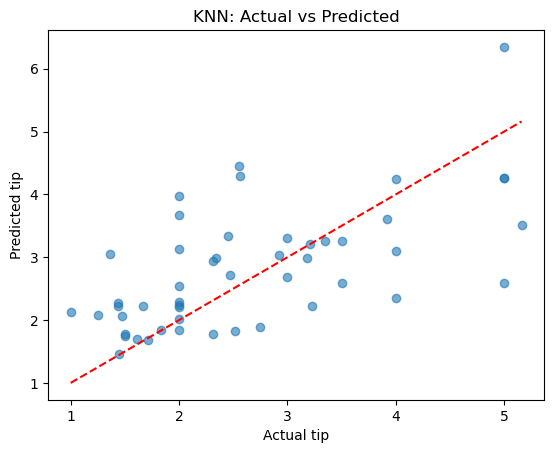

In [103]:
import matplotlib.pyplot as plt
plt.scatter(ytest, knn_model.predict(xtest), alpha=0.6)
plt.plot([ytest.min(), ytest.max()], [ytest.min(), ytest.max()], 'r--')
plt.xlabel('Actual tip'); plt.ylabel('Predicted tip'); plt.title('KNN: Actual vs Predicted')
plt.show()


In [104]:
sns.load_dataset('iris')

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [105]:
iris = sns.load_dataset('iris')

In [106]:
model = knn_model = KNeighborsRegressor(n_neighbors=5).fit(xtrain, ytrain)
model.score (xtest, ytest)

0.3078597253641333

### KNN Classification on Iris Dataset
- Predict iris species using K-Nearest Neighbors classifier.

In [107]:
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Encode species as numeric labels
le = LabelEncoder()
iris["species_encoded"] = le.fit_transform(iris["species"])

# Features and target
X_iris = iris[["sepal_length", "sepal_width", "petal_length", "petal_width"]].values
y_iris = iris["species_encoded"].values.reshape(-1, 1)

# Train/test split
xtrain_i, xtest_i, ytrain_i, ytest_i = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42)

# KNN classifier
knn_clf = KNeighborsClassifier(n_neighbors=5).fit(xtrain_i, ytrain_i)
acc = accuracy_score(ytest_i, knn_clf.predict(xtest_i))
print("KNN accuracy:", round(acc, 4))

# Confusion matrix
cm = confusion_matrix(ytest_i, knn_clf.predict(xtest_i))
print("\nConfusion Matrix:\n", cm)

# Predict a new flower: sepal_length=5.1, sepal_width=3.5, petal_length=1.4, petal_width=0.2
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
pred_species = knn_clf.predict(new_flower)
print("\nPredicted species:", le.inverse_transform(pred_species)[0])


KNN accuracy: 1.0

Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Predicted species: setosa


c:\Users\jimmy\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:228: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [ ]:
# Compute Euclidean distance from each test sample to the new flower
from scipy.spatial.distance import euclidean

distances = np.array([euclidean(x, new_flower[0]) for x in xtest_i])
print("Euclidean distances from new flower to each test sample (first 10):")
print(np.round(distances[:10], 4))

# Find the 5 nearest neighbors by distance
nearest_idx = np.argsort(distances)[:5]
print("
Indices of 5 nearest neighbors:", nearest_idx)
print("Their true species:", le.inverse_transform(ytest_i[nearest_idx].flatten()))
print("Their predicted species:", le.inverse_transform(knn_clf.predict(xtest_i[nearest_idx]).flatten()))


In [ ]:
# Compare actual vs predicted species for the test set
actual = le.inverse_transform(ytest_i.flatten())
predicted = le.inverse_transform(knn_clf.predict(xtest_i).flatten())

results = pd.DataFrame({"Actual": actual, "Predicted": predicted})
print("First 15 test predictions:")
print(results.head(15).to_string(index=False))

# Count mismatches
mismatch = results["Actual"] != results["Predicted"]
print("
Total mismatches:", mismatch.sum(), "out of", len(results))


In [ ]:
# Compute accuracy score explicitly
from sklearn.metrics import accuracy_score

acc_score = accuracy_score(ytest_i, knn_clf.predict(xtest_i))
print("Accuracy score:", round(acc_score, 4))
print("Interpretation: {:.1f}% of test samples were classified correctly.".format(acc_score * 100))
